# Lesson 7: Resistance, the Double Layer and the Cell Time Constant
The last lesson established what an electrochemical cell is made of. Ions still have to move between those electrodes, and that movement is not free. This lesson works out what it costs you, and introduces a timescale that limits every experiment in the rest of the course.

Today's topics:
- Solution resistance and where you put the reference electrode
- How uncompensated resistance distorts real data
- The electrical double layer and the cell time constant

**Reference:**
- Sections 1.2, 1.3 and 13.1 in *Electrochemical Methods: Fundamentals and Applications*, Allen J. Bard & Larry R. Faulkner.
---

## Configure Environment

In [3]:
import sys
if '../Resources' not in sys.path:
    sys.path.append('../Resources')     # so that echem.py can be found

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
import ipywidgets as widgets
from IPython.display import display
import schemdraw                        # NEW! for drawing circuit diagrams
import schemdraw.elements as elm

import echem                            # the shared toolkit for this course
from echem import R, T, F, f           # physical constants
echem.use_style()                       # course-wide graph formatting

# 1. Experimental Considerations

#### Ionic Charge Transport
- Attention is usually focused on electron transfer processes, but it is important to note that electronic charge transport must be mirrored by **ionic charge transport**

- **Solution resistance** ( $R_s$ ) reflects **ionic conductivity** between electrodes

- $R_s$ results in a loss of energy during experiments, following Ohm's Law 

 $\large E_{lost} = i \cdot R_s$ 

- Strategies to reduce $R_s$ exist, but some uncompensated resistance ( $R_u$ ) always remains

 $\large E_{lost} = i \cdot R_u$ 

- Strategies to minimize $R_s$ :
 - Change **solvent** (dielectric constant can be a useful guide)
 - "Good" solvents: H $_2$ O ( $\epsilon$ ≈ 80), acetonitrile ( $\epsilon$ ≈ 38), propylene carbonate ( $\epsilon$ ≈ 64)
 - "Bad" solvents: hexane (e ≈ 2), toluene (e ≈ 2)
 - Change **electrolyte species** and/or increase its concentration
 - High solubility limits and high ionic diffusion coefficients help
 - Increase **temperature** of the cell
 - Ionic diffusion coefficients increase with temperature
 - **Placement of electrodes**
 - Minimize WE-CE distance (2-electrode cells) or WE-RE distance (3-electrode cells)
 
#### Electrode Placement
Resistance due to the electrolyte solution, both $R_u$ and $R_s$ , is proportional to distance between the electrodes.

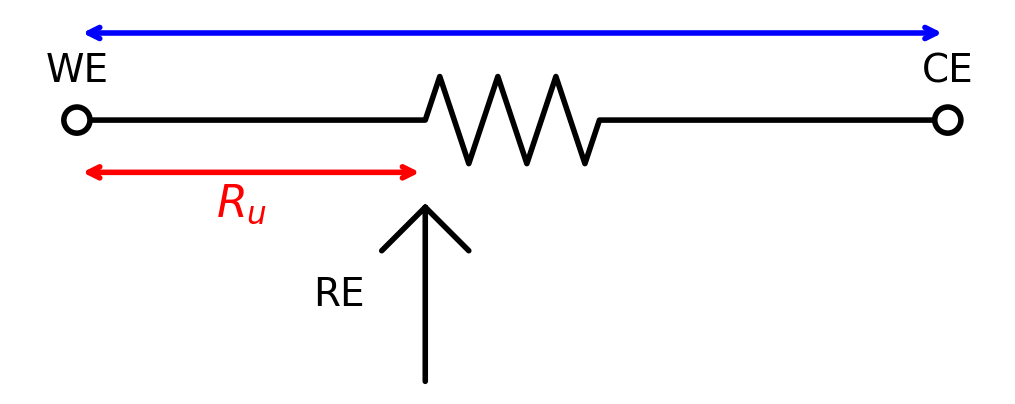

In [2]:
soln_resistance = schemdraw.Drawing(inches_per_unit=1)

soln_resistance.add(elm.Dot(open=True).label('WE'))
soln_resistance.add(elm.Resistor().length(5))
soln_resistance.add(elm.Dot(open=True).label('CE'))
soln_resistance.add(elm.Gap().label('').length(1.5).down())
soln_resistance.add(elm.Gap().label('').length(3.).left())
soln_resistance.add(elm.Plug(open=True).label('RE').up())

# annotate diagram
fig = soln_resistance.draw()

fig.ax.annotate(r'$R_s$ proportional to distance', (0.7, 0.7), fontsize=16, color='blue')
fig.ax.annotate('', 
            xy=(0, 0.5), xycoords='data', 
            xytext=(5, 0.5), textcoords='data',
            fontsize=10, arrowprops=dict(arrowstyle='<->', 
                                         color='blue',
                                         linewidth=2)
               )

fig.ax.annotate(r'$R_u$', (0.8, -0.55), fontsize=16, color='red')
fig.ax.annotate('', 
            xy=(0, -0.3), xycoords='data', 
            xytext=(2, -0.3), textcoords='data',
            fontsize=10, arrowprops=dict(arrowstyle='<->', 
                                         color='red',
                                         linewidth=2
                                        )
               )

display(fig)

The ability to control placement of the reference electrode therefore provides a means to decrease overall resistance in the system:

In [ ]:
@interact(d=widgets.FloatSlider(value=0.5, min=0, max=0.99, step=0.01,
                                description='RE position'),
          r=widgets.FloatText(value=10., step=0.1, description=r'$R_s (\Omega)$'),
          i=widgets.FloatText(value=0.1, step=0.001, description=r'$i$ (A)'))
def plot_electrode_placement(d, r, i):
    '''Where you put the reference electrode decides how much resistance you fight.'''
    fig = plt.figure()
    ax = plt.subplot(111)
    ax.set_xlabel('Normalized Distance')
    ax.set_ylabel('E')
    ax.plot([0, 1], [1, 0], ':')
    ax.plot([-0.1, 0.1], [1, 1], 'k')
    ax.plot([0.9, 1.1], [0, 0], 'k')
    ax.set_ylim(-0.2, 1.2)
    ax.set_yticks([])

    ax.annotate('WE', (-0.05, 1.05), color='black')
    ax.annotate('CE', (0.95, -0.1), color='black')
    ax.annotate(rf'$iR_s$ = {i*r:.3f} V', (0.75, 1.05), color='red')
    ax.annotate('', xy=(1, 1), xycoords='data', xytext=(1, 0), textcoords='data',
                fontsize=10, arrowprops=dict(arrowstyle='<->', color='red'))

    ax.annotate('RE', (d - 0.05, 1 - d + 0.05), color='black')
    ax.plot([d - 0.1, d + 0.1], [1 - d, 1 - d], 'k')
    ax.annotate(rf'$iR_u$ = {i*r*d:.3f} V', (0.05, 0.3), color='blue')
    ax.annotate('', xy=(0, 1), xycoords='data', xytext=(0, 1 - d), textcoords='data',
                fontsize=10, arrowprops=dict(arrowstyle='<->', color='blue'))

interactive(children=(FloatSlider(value=0.5, description='RE position', max=0.99, step=0.01), FloatText(value=…

#### Luggin Capillaries

The interactive diagram above hopefully convinced you of the importance of electrode placement, and of the utility of three electrode cells. The addition of a reference electrode enables the study of electron transfer processes under conditions that are simply impossible with a two electrode apparatus.

Depending on your reference electrode and the geometry of your electrochemical cell, the placement of its important surface near your working electrode might be downright impossible without clever engineering. Some electrodes, for example, must be held vertical, some have diameters that measure in the cm scale, and sometimes you need to work in very small volumes of solutions. Such problems led to the discovery of **Luggin capillaries**. A Luggin capillary is a tube that holds a reference electrode and can be inserted into an electrochemical cell. The tube curves 90-degrees and comes to a fine hollow point (ie, a capillary) that is < 1 mm in diameter. This geometry allows the capillary to be placed very close to an electrode surface even in challenging situations. The tip of the capillary effectively acts as the reference electrode, allowing $iR_u$ to be minimized.

<img src='../Resources/images/luggin.jpg' width=400>

The design of Luggin capillaries is simple and there are many iterations on the theme. Some examples:
- [Pine Research](https://pineresearch.com/shop/products/corrosion-products/corrosion-accessories/rce-luggin-tube/)
- [Hilgenberg](https://www.hilgenberg-gmbh.de/en/product-novelties/luggin-capillary/)
- [Variations on Ali-Baba](https://www.aliexpress.com/item/4000057385173.html)
- [A custom designed version](https://link.springer.com/protocol/10.1007/978-1-62703-794-5_6#Fig4)
- [A second custom version](https://link.springer.com/chapter/10.1007/978-3-642-36188-3_7#Fig00073)

# 2. How Resistance Affects Behavior

The voltage experienced at the surface of the working electrode is the voltage applied between the **WE** and **CE**, minus that lost to resistance (Ohm's law):

$
\large E_{WE} = E_{applied} - i \cdot R_s
$

The $R_s$ value can be expected to be constant based on your electrochemical cell, but the $i$ passed will depend on the chemistry occurring at the electrode surface. The simplest effect of high resistance values is therefore distortion of the data by stretching the x-axis in a non-uniform fashion.

Introduction of an **RE** to form a **3-electrode cell** enables us to ignore a portion of $R_s$ . That full solution resistance still exists between the **WE** and **CE**, but the voltage that we now see is that between the **WE** and **RE**. This voltage is only affected by $R_u$ :

$
\large E_{WE} = E_{applied} - i \cdot R_u
$

The effect of resistance can therefore be approximated by selecting either $E_{WE}$ or $E_{applied}$ as the value plotted on the x-axis:


In [5]:
# A real cyclic voltammogram of a Ni(OH)2 film.  Rows 901 onwards are the second
# cycle, which is the stable one.
cv = np.loadtxt('../Resources/data/CV-NiHydroxide.csv', delimiter=',')
SECOND_CYCLE = slice(901, None)
potential = cv[SECOND_CYCLE, 0]
current = cv[SECOND_CYCLE, 1]

@interact(r=widgets.FloatSlider(value=0., min=0., max=50., step=1.,
                                description=r'$R_u$ added'))
def plot_resistance_cv(r):
    '''Add uncompensated resistance to clean data and watch the peaks move apart.'''
    fig = plt.figure()
    ax = plt.subplot(111)
    ax.set_xlabel('E /V vs. RHE')
    ax.set_ylabel('i /mA')
    ax.plot(potential, current*1000, label=r'$R_u$ added = 0')
    ax.plot(potential + current*r, current*1000, label=rf'$R_u$ added = {r:.0f} $\Omega$')
    ax.legend(fontsize=6, loc=2)

interactive(children=(FloatSlider(value=0.0, description='$R_u$ added', max=50.0, step=1.0), Output()), _dom_c…

In the relatively straightforward cyclic voltammogram (CV) above, resistance has several obvious impacts on the data:
1. Both the anodic and cathodic peaks shift to *more extreme potentials*
2. There is an *apparent* decrease in electron transfer kinetics

The exponential increase in currents in the CV at potentials above ~1.4 V vs. RHE shows the relationship between thermodynamics (potential) and kinetics (current). Being exponential, it is common to see electron transfer kinetics analyzed using semi-logarithmic plots:

In [6]:
# The same data on a logarithmic current axis, zoomed onto the rising edge.
# Rows 1200 to 1350 cover the onset of the anodic wave.
ONSET = slice(1200, 1350)
potential_onset = cv[ONSET, 0]
current_onset = cv[ONSET, 1]

@interact(r=widgets.FloatSlider(value=0., min=0., max=50., step=1.,
                                description=r'$R_u$ added'))
def plot_resistance_tafel(r):
    '''On a log axis, resistance shows up as curvature: an apparent loss of kinetics.'''
    fig = plt.figure()
    ax = plt.subplot(111)
    ax.set_xlabel('E /V vs. RHE')
    ax.set_ylabel('i /mA')
    ax.plot(potential_onset, current_onset*1000, label=r'$R_u$ added = 0')
    ax.plot(potential_onset + current_onset*r, current_onset*1000,
            label=rf'$R_u$ added = {r:.0f} $\Omega$')
    ax.set_yscale('log')
    ax.legend(fontsize=6, loc=2)

interactive(children=(FloatSlider(value=0.0, description='$R_u$ added', max=50.0, step=1.0), Output()), _dom_c…

The results obtained during an experiment are clearly dependent on a user's ability to minimize resistance in the cell!

It may occasionally be possible to **correct for resistance** by measuring $R_u$ and applying the equation above. This effectively converts $E_{applied}$ into $E_{WE}$ . Exercise caution, however, because the data cannot always be appropriately corrected, and it is very easy to overcorrect your data.

In the world of batteries, resistance has a similar effect. The data below shows the discharge of a LiCoO $_2$ electrode, where higher $C$ values correspond to discharging the battery using larger $i$ values.

<img src='../Resources/images/gsm-discharges-liion.jpg' width=50%>

The discharge involves a reduction of cobalt ions:

$
Li_{1-x}CoO_2 + xLi^+ + xe^- \rightleftharpoons LiCoO_2
$

Which occurs near ~3.8 V when paired with a lithium metal anode. The resistive effects in the battery cell used above show a shift to lower voltages, which is easily understood through Ohm's law.

# 3. Additional Considerations

It is important to understand that resistance arises due to difficulty transferring ionic charge. The accumulation of both **electronic** and **ionic** charge at an electrode surface is intimately related to our understanding of how electron transfer reactions work. In short, resistance does not simply change the voltage at the surface, it changes the chemistry that is happening. Experimental parameters become incorrect, and theoretically predicted behavior may never be salvaged from the data. "High" $R_u$ values not only result in energy loss, but also make it very difficult to have confidence in analyses of results.

To understand this, the concept of the **electrical double layer** needs to be introduced.

<div class="alert alert-block alert-success">
<b>Electrical double layer</b>: The region at an electrode surface where electronic charge and ionic charge neutralize each other.
</div>

Text(0.8, 0.82, '$\\phi_{soln}$')

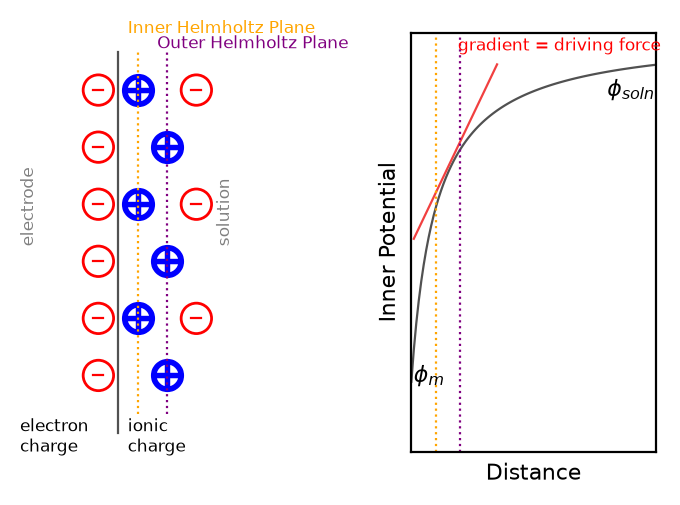

In [7]:
fig = plt.figure()
ax1 = plt.subplot(121)
ax2 = plt.subplot(122)

ax1.set_xlim(-0.1, 0.15)
ax1.plot([0,0],[0,1])
ax1.annotate('electrode', (-0.1, 0.5), fontsize=6, color='gray', rotation=90)
ax1.annotate('solution', (0.1, 0.5), fontsize=6, color='gray', rotation=90)


ax1.scatter([-0.02]*6, [0.9, 0.75, 0.6, 0.45, 0.3, 0.15], facecolors='none', edgecolors='red', s=120)
for d in [0.9, 0.75, 0.6, 0.45, 0.3, 0.15]:
    ax1.plot([-0.025, -0.015], [d, d], color='red')
    
ax1.scatter([0.08]*3, [0.9, 0.6, 0.3], facecolors='none', edgecolors='red', s=120)
for d in [0.9, 0.6, 0.3]:
    ax1.plot([0.075, 0.085], [d, d], color='red')    
ax1.annotate('electron\ncharge', (-0.1, -0.05), fontsize=6, color='black')
ax1.annotate('ionic\ncharge', (0.01, -0.05), fontsize=6, color='black')


ax1.scatter([0.02]*3, [0.9, 0.6, 0.3], facecolors='blue', edgecolors='blue', marker='$\\bigoplus$', s=120)
ax1.plot([0.02]*2, [0.05, 1], linestyle=':', color='orange')
ax1.annotate('Inner Helmholtz Plane', (0.01, 1.05), color='orange', fontsize=6)

ax1.scatter([0.05]*3, [0.75, 0.45, 0.15], facecolors='blue', edgecolors='blue', marker='$\\bigoplus$', s=120)
ax1.plot([0.05]*2, [0.05, 1], linestyle=':', color='purple')
ax1.annotate('Outer Helmholtz Plane', (0.04, 1.01), color='purple', fontsize=6)

ax1.set_frame_on(False)
ax1.set_xticks([])
ax1.set_yticks([])

d = np.linspace(0,1,100)
y = 1-(1)/(1+10*d)
ax2.set_xlabel('Distance')
ax2.set_ylabel('Inner Potential')
ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_xlim(0, 1)
ax2.set_ylim(-0.2, 1)
ax2.plot(d, y)
ax2.plot([0.01, 0.35], [0.41, 0.91])
ax2.axvline(0.1, linestyle=':', color='orange')
ax2.axvline(0.2, linestyle=':', color='purple')
ax2.annotate('gradient = driving force', (0.19, 0.95), fontsize=6, color='red')
ax2.annotate(r'$\phi_m$', (0.01, 0), fontsize=8)
ax2.annotate(r'$\phi_{soln}$', (0.8, 0.82), fontsize=8)

Application of a voltage to the electrode results in electronic charge (positive or negative) accumulation at the electrode surface with opposing ions attracted to the interface. An **electric field** is formed between the two opposing charges. This electric field establishes the driving force for electron transfer across the interface. Electron transfer will not happen without the electric field; the electrical double layer is therefore an absolute necessity for electrochemical reactions.

The structure of the electrical double layer is believed to be roughly made up by *layers* of charge. The electric charge at the surface of the solid state material (our electrode) is counterbalanced by attraction of ions. These ions can be **specifically adsorbed** to the surface, which means that their solvation shell has been removed. They are therefore in direct contact with the solid surface. The **inner Helmholtz plane** is a 2-D plane drawn through the center of these ions. The **outer Helmholtz plane** is a plane that is drawn through ions that remain solvated - the solvent molecules hold them further away from the surface, which places the OHP at a greater distance than the IHP. The ions immediately adjacent to the electrode surface are primarily the opposing charge to that on the surface. Because like-charges repel, there is believed to be a second layer of opposing ions. The charge density rapidly dies off as distance from the electrode increases, resulting in a loss of such ordering.

The charge passed per unit potential to establish the electrical double layer is referred to as **double layer capacitance**, or $C_{dl}$ . A common assumption is that $C_{dl} \approx 20 \mu F \cdot cm^{-2}$ . This assumption originates from the charging of metallic platinum surfaces. Be wary, however, because this value varies with electrode material and composition of electrolyte solution. For example, glassy carbon electrodes (amorphous, conducting carbon) are ~20-30 $\mu F \cdot cm^{-2}$ , whereas the basal plane of highly oriented pyrolytic graphite (HOPG) is only ~5 $\mu F \cdot cm^{-2}$ .

The double layer is effectively a capacitor, meaning that the current flow to charge it can be described as:

$
\large i_{dl} = \frac{E}{R_s}e^{-\frac{t}{R_sC_{dl}}}
$

<div class="alert alert-block alert-info">
<b>Practice problem:</b>
<br>
Interact with the figure below and take note of what each parameter does. What is the difference between the left and right panels?
</div>

In [ ]:
from echem import WIDE
@interact(r=widgets.FloatSlider(value=20., min=1., max=50., step=1., description=r'$R_s (\Omega)$'),
          cdl_uF=widgets.FloatText(value=20., description=r'$C_{dl} (\mu F)$'),
          e_step=widgets.FloatSlider(value=0.05, min=0.001, max=0.2, step=0.01,
                                     description=r'$E_{step}$ (V)'))
def plot_double_layer_charging(r, cdl_uF, e_step):
    '''Charging the double layer through the solution resistance: an RC transient.'''
    cdl = cdl_uF * 1e-6                 # convert microfarads to farads
    tau = r * cdl                       # the cell time constant, seconds

    fig = plt.figure(figsize=WIDE)
    ax1 = plt.subplot(121)
    ax2 = plt.subplot(122)

    # Left panel: the real transient, in real units
    t = np.linspace(tau/1000, 10*tau, 100)
    ax1.plot(1000*t, 1000*(e_step/r)*np.exp(-t/tau), 'blue')
    ax1.set_xlim(0, 10000*tau)
    ax1.set_xlabel('time (ms)')
    ax1.set_ylabel('i (mA)')
    ax1.set_title(rf'$\tau$ = {1000*tau:.2f} ms', fontsize=8)

    # Right panel: the same curve with time measured in units of tau.  Every
    # RC cell in the world collapses onto this one line.
    t_norm = np.linspace(0.01, 10, 100)
    ax2.plot(t_norm, np.exp(-t_norm), 'blue')
    ax2.set_ylabel(r'$i/i(t=0)$')
    ax2.set_xlabel(r't ($\tau$)')
    for multiple in [1, 3, 5]:
        ax2.axvline(multiple, 0, np.exp(-multiple), linestyle=':', c='gray')
        ax2.axhline(np.exp(-multiple), xmax=multiple/10, linestyle=':', c='gray')
    # All three labels quote the SAME quantity: the percentage of charging COMPLETED.
    ax2.annotate(r'$1\tau$: 63% charged', (1.2, 0.40), fontsize=8)
    ax2.annotate(r'$3\tau$: 95% charged', (3.0, 0.15), fontsize=8)
    ax2.annotate(r'$5\tau$: 99% charged', (5.0, 0.06), fontsize=8)
    ax2.set_xlim(0, 10)
    ax2.set_ylim(0, 1)

interactive(children=(FloatSlider(value=20.0, description='$R_s (\\Omega)$', max=50.0, min=1.0, step=1.0), Flo…

Hopefully you noticed that each parameter affects the behavior in a different fashion:
- increasing $R_s$ increases the time required to fully charge the double layer; it also decreases the maximum current attained
- increasing $E_{step}$ increases the electronic charge for equilibration, which results in larger current flows
- increasing $C_{dl}$ increases the charge that can be stored at the surface, which results in larger current flows; it also increases the time required to charge

Hopefully you also noticed that the shape of the curve in both panels was always the same: the scales changed on the left, but the curves themselve didn't. The panel on the right demonstrates the **dimensionless** perspective. **Dimensionless parameters** are very powerful in electrochemistry. These parameters enable generalization of behavior. In this particular situation, the second panel plots time normalized by the **characteristic time (time constant)**, $\tau$ . The exponent in the $i_{dl}$ equation must be unitless, meaning that the units of $R_s \cdot C_{dl}$ must be seconds. 

<div class="alert alert-block alert-danger">
<b>Check your units!</b>
<br>
Definition: $\large 1F = \frac{1C}{1V} = \frac{1A \cdot 1s}{1V}$ 
<br>
From Ohm's law:
<br>
 $\large R = \frac{E}{i}$ 
<br>
 $\large \Omega = \frac{V}{A}$ 
<br>
Therefore:
<br>
 $\large \frac{V}{A} \cdot \frac{1A \cdot 1s}{1V} = s$ 
</div>

We can therefore define the characteristic time (time constant):

 $\large \tau = R_s \cdot C_{dl}$ 

The second panel in the figure shows the **x-axis** normalized by $R_s \cdot C_{dl}$ such that it is in units of $\tau$ , and the **y-axis** normalized to the maximum current at $t=0$ .

<div class="alert alert-block alert-success">
<b>Electrochemical time constant</b>: The time required to establish the electrical double layer at an electrode surface. <b>This value is critically important!</b>
</div>

Practically, $\tau$ is the time required for $I_{dl}$ to decrease to 37% of its initial value. The mathematical definition makes it clear that this timeframe is dependent on solution resistance and double layer capacitance for the electrode.

Qualitatively, $\tau$ can be understood as the time necessary to establish a new potential (voltage) at an electrode surface. Always remember that the voltage experienced at the electrode surface is entirely dependent on the electrical double layer; *the voltage is not fully established until the double layer is properly formed*. 

It is important to note that at time $\tau$ , only 2/3 of the total charge has been passed. The double layer is not yet established at time $\tau$ . One must therefore consider multiples of $\tau$ when designing experiments: data recorded at times below $3\tau$ are inaccurate. Better yet, times of $5\tau$ should be used.

Assuming a $C_{dl}$ of 20 $\mu$ F:

| $R_s$ | $\tau$ (ms)| $3\tau$ (ms)|
|---|---|---|
|1|0.02|0.06|
|10|0.2|0.6|
|100|2|6|
|1000|20|60|

---
# Literature Examples: Double Layer Capacitance
It is not uncommon to see the assumption that double layer capacitance is constant at some value and that it is predictable in nature. However, there is evidence that such assumptions are risky. For example:

#### Surface Chemistry

[J. Am. Chem. Soc. 1994, 116, 5444](https://doi.org/10.1021/ja00091a057)

**Experiment**: an Os(II) polypyridyl complex was adsorbed on an electrode surface. The electrode behavior was subsequently analyzed. The measured $C_{dl}$ values were found to be a function of the oxidation state of the transition metal complex.

<img src='../Resources/images/1994JACS.png' width=30%>

#### Experimental Protocols

[Langmuir 2014, 30, 9591](https://doi.org/10.1021/la501669a)

Experimental conditions such as a change electrolyte solution composition can affect even the most basic properties. An example showing the impact of solution pH on cell time constant ( $\tau$ ):

<img src='../Resources/images/2014Langmuir1.png' width=30%>

<img src='../Resources/images/2014Langmuir2.png' width=30%>

Note that the 1 to 4 second $\tau$ values necessitate **3 to 12 seconds** to equilibrate voltage.

#### Electrode Materials

[Nature Communications 2014, 5, 3317](https://www.nature.com/articles/ncomms4317)

 $C_{dl}$ often exhibits non-linear behavior, and the nanostructure of the material being used can have dramatic influence. Below, $C_{dl}$ for graphene is shown to have a V-shaped dependence on voltage, where the minimum corresponds to the **point of zero charge**. The magnitude of $C_{dl}$ is also shown to be dependent on the number of individual graphene layers that are stacked upon each other.

<img src='../Resources/images/graphene.png' width=50%>

<img src='../Resources/images/graphenecdl.png' width=50%>

<div class="alert alert-block alert-info">
<b>Activity:</b> You are about to run an experiment that needs to resolve a current transient lasting 1 ms.
<br>
Using the $\tau$ table above, decide whether that is possible in a cell with $R_s$ = 100 $\Omega$ and $C_{dl}$ = 20 $\mu$ F. If it is not, list every change you could make to the cell to make it possible, and say which one you would try first.
</div>

- Possible as it stands? ANSWER
- Changes available to me: ANSWER
- What I would try first, and why: ANSWER